In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [121]:
df = pd.read_csv('customer churn.csv')

In [122]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [123]:
print(df.shape)

(7043, 21)


In [124]:
#Inspection of the dataset part 1 for  analysis

In [125]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [126]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0").astype(float)   # replace the blank values with 0 and convert the column to float

In [127]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [128]:
df.isnull().sum() # check for null values in the dataset

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [129]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [130]:
df.duplicated().sum() # check for duplicate values in the dataset

np.int64(0)

In [131]:
df["customerID"].duplicated().sum()

np.int64(0)

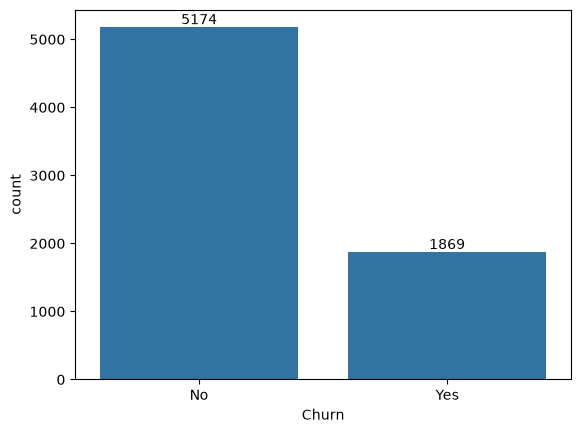

In [132]:
# sns.countplot(x="Churn", data=df) # to visualize the distribution of the target variable "Churn"
ax = sns.countplot(x="Churn", data=df)
for container in ax.containers:
    ax.bar_label(container)

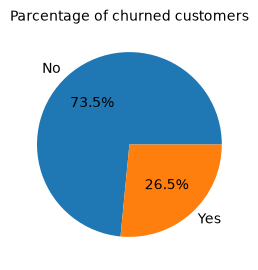

In [133]:
plt.figure(figsize=(3,3))
gb = df.groupby("Churn").agg({'Churn': "count"})
plt.pie(gb['Churn'], labels=gb.index, autopct="%.1f%%")
plt.title("Parcentage of churned customers", fontsize = 10)
plt.show()

From the chart 26.5 % of our customers have churned out
 now let

Text(0.5, 1.0, 'Churn by gender')

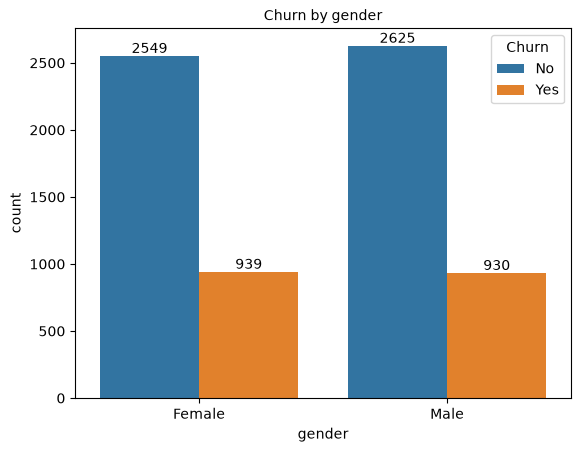

In [134]:
ax = sns.countplot(x="gender", data=df, hue="Churn")
for container in ax.containers:
    ax.bar_label(container)
plt.title ("Churn by gender", fontsize = 10)

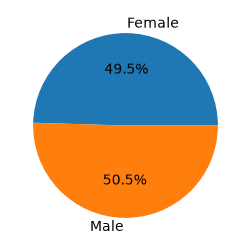

In [135]:
plt.figure(figsize=(3,3))
gb = df.groupby("gender").agg({'gender': "count"})
plt.pie(gb['gender'], labels=gb.index, autopct="%.1f%%")
plt.show()

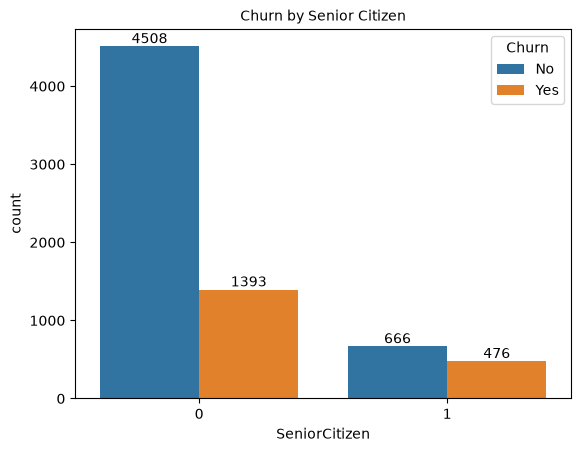

In [ ]:
ax = sns.countplot(x="SeniorCitizen", data=df, hue="Churn")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Churn by Senior Citizen", fontsize=10)
plt.show()

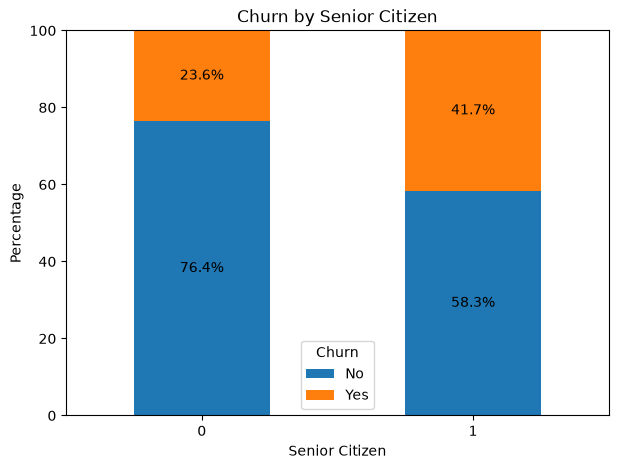

In [137]:
# Create count table
ct = pd.crosstab(df["SeniorCitizen"], df["Churn"])

# Convert counts to percentages
ct_percent = ct.div(ct.sum(axis=1), axis=0) * 100

# Plot 100% stacked bar
ax = ct_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5)
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center"
    )

plt.title("Churn by Senior Citizen")
plt.xlabel("Senior Citizen")
plt.ylabel("Percentage")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

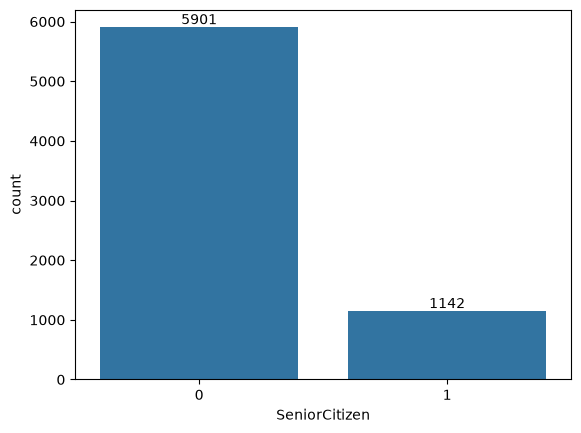

In [138]:
plt.Figure(figsize=(5,4))
ax = sns.countplot(x="SeniorCitizen", data=df)

for container in ax.containers:
    ax.bar_label(container)
plt.show()

cpmpetitive a greater percentage of people in senior citizen category have Churned.

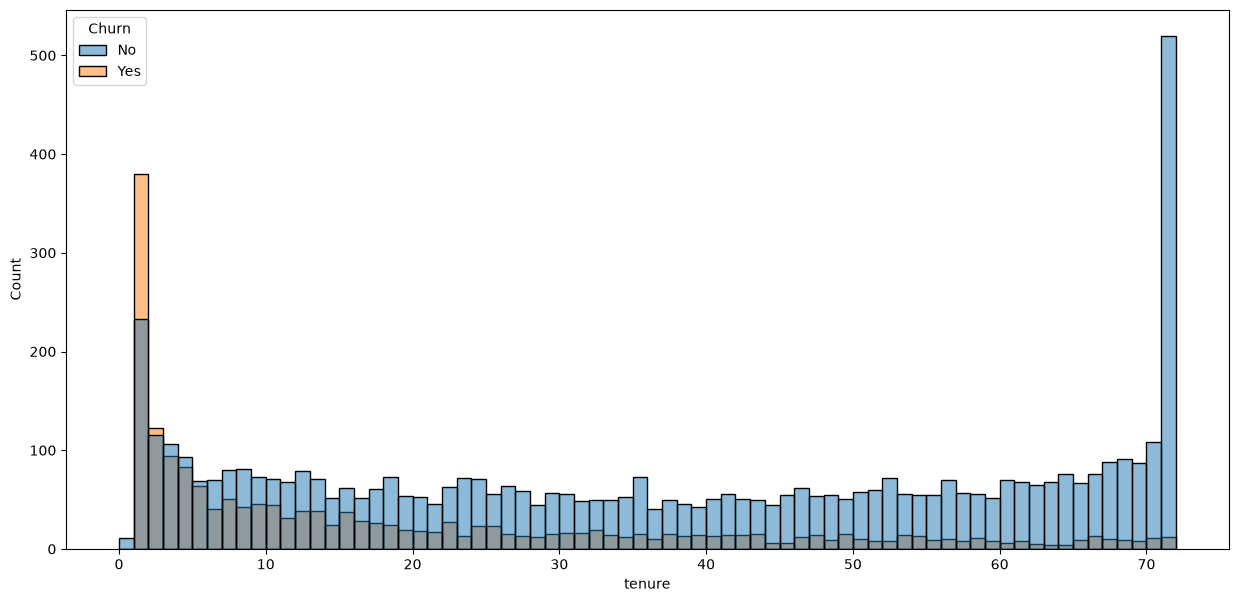

In [139]:
plt.figure(figsize=(15, 7))
sns.histplot(x = "tenure", data=df, bins=72, hue = "Churn")
plt.show()

people who has uses our sevises for a long time stayed and who have uses our services oneor two month and churned out.

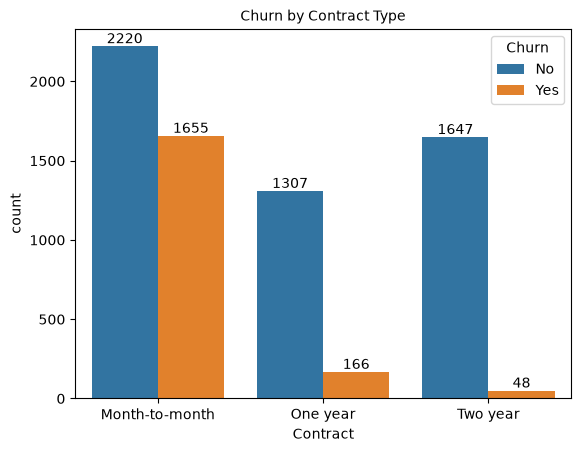

In [143]:
ax = sns.countplot(x="Contract", data=df, hue="Churn")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Churn by Contract Type", fontsize=10)
plt.show()

people who have contract are likely to churned then from those who have 1 or 2 years of contract

In [145]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

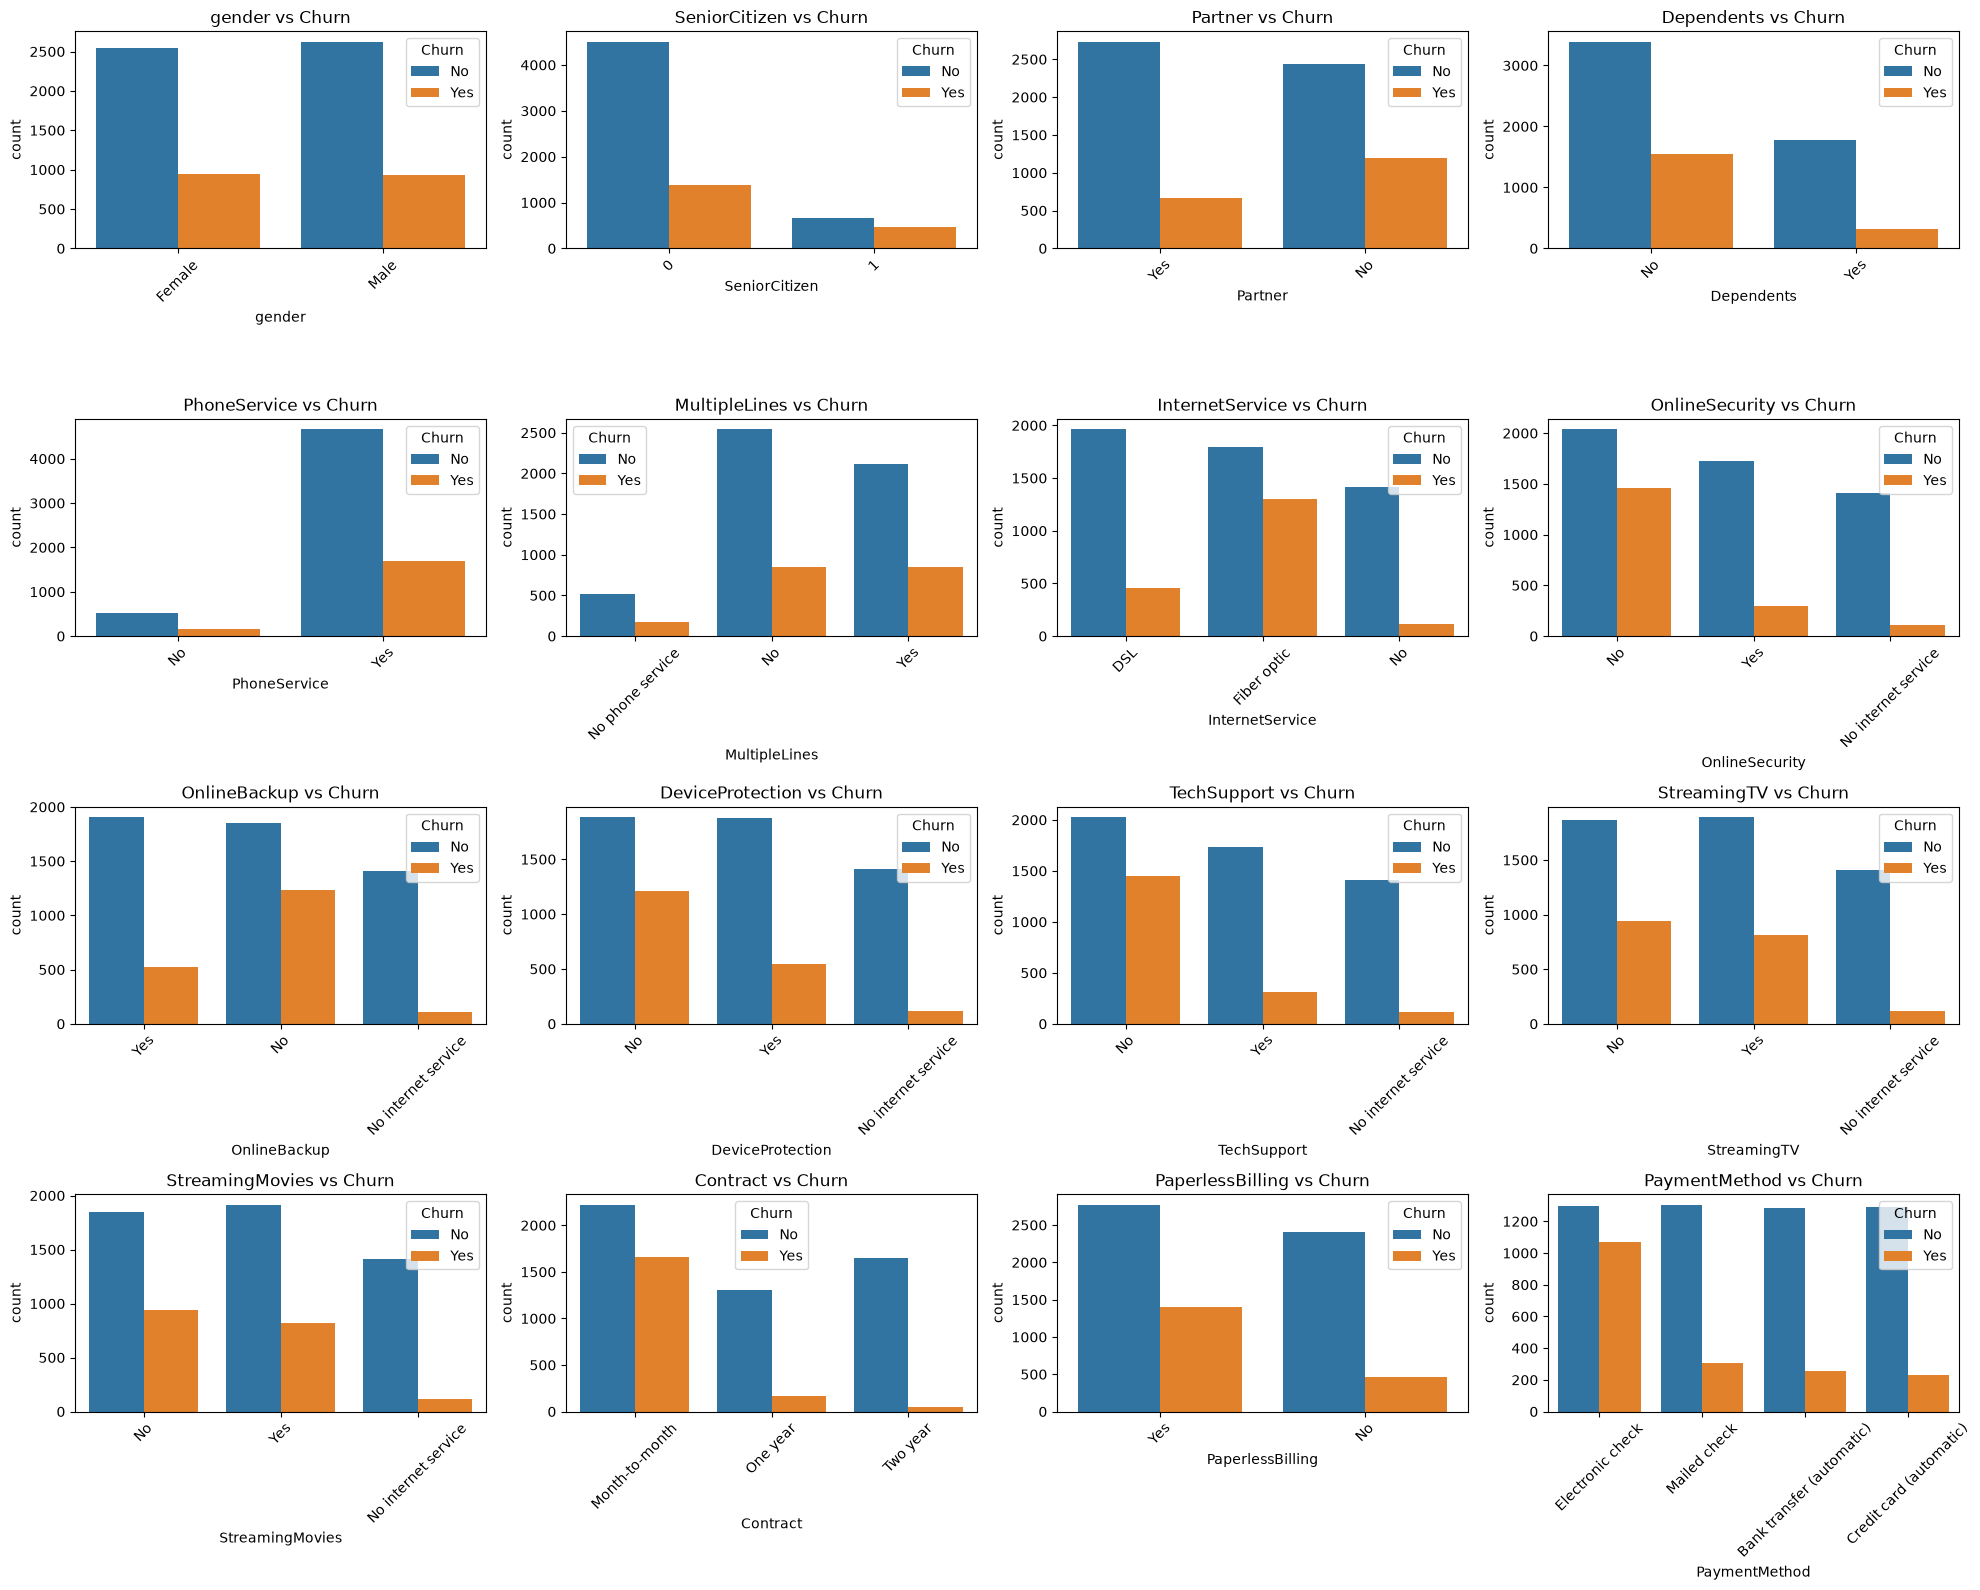

In [150]:
cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flat, cols):
    sns.countplot(data=df, x=col, ax=ax, hue='Churn')
    ax.set_title(f'{col} vs Churn')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

These countplots show the distribution of customers across different demographic, service, and contract categories.
The Churn hue helps compare customers who stayed versus those who left.
Variables such as Contract, InternetService, TechSupport, and OnlineSecurity can help identify patterns related to customer churn.
Overall, the charts provide a quick visual overview of which customer groups have higher or lower churn.

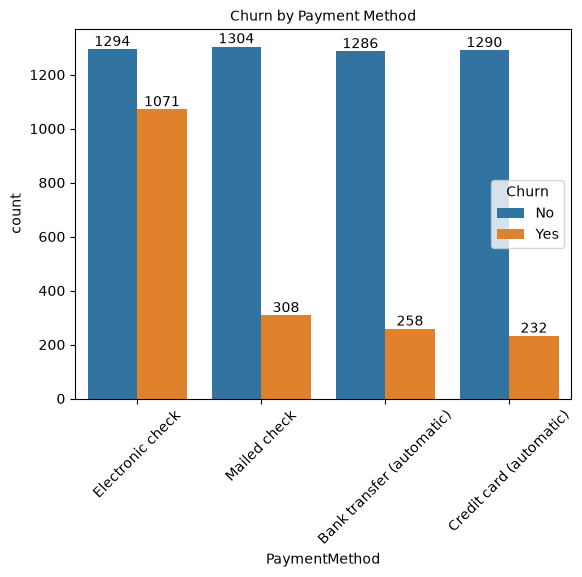

In [152]:
ax = sns.countplot(x="PaymentMethod", data=df, hue="Churn")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Churn by Payment Method", fontsize=10)
plt.xticks(rotation=45)
plt.show()